# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
#LabelEncoder: una sola columna con números enteros
print(data[['sex', 'sex_label']].head())
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

#OneHotEncoder (get_dummies): una columna binaria por categoría
print(data[['embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head())

      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1
{'female': np.int64(0), 'male': np.int64(1)}
  embarked  embarked_C  embarked_Q  embarked_S
0        S       False       False        True
1        C        True       False       False
2        S       False       False        True
3        S       False       False        True
4        S       False       False        True


LabelEncoder convierte cada categoría en un número entero dentro de una sola columna (female=0, male=1), mientras que OneHotEncoder crea una columna binaria por categoría (embarked_C, embarked_Q, embarked_S).

LabelEncoder es compacto pero impone un orden numérico entre categorías; OneHotEncoder evita ese orden a costa de agregar más columnas.

In [ ]:
pd.get_dummies(data['embarked'], dummy_na=True)

,C,Q,S,NaN
0,False,False,True,False
1,True,False,False,False
2,False,False,True,False
3,False,False,True,False
4,False,False,True,False
...,...,...,...,...
886,False,False,True,False
887,False,False,True,False
888,False,False,True,False
889,True,False,False,False


La columna embarked tiene 2 valores faltantes en Titanic; con get_dummies quedan en 0 en las tres columnas, y con dummy_na=True se les crea una columna propia

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

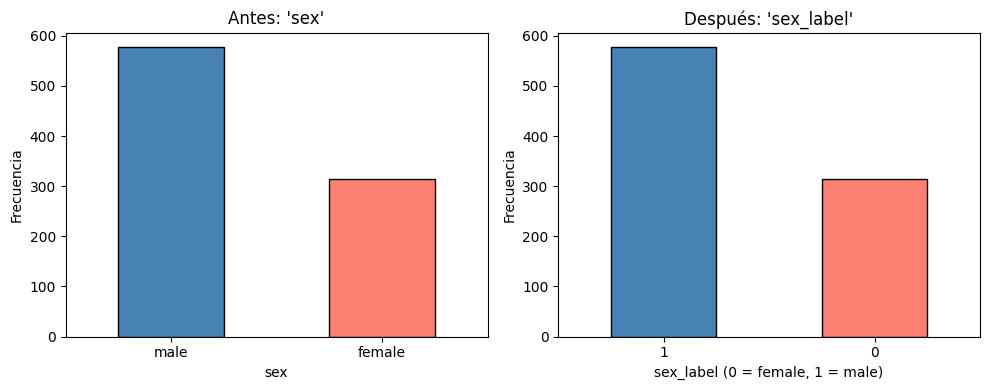

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Antes: categorías originales
data['sex'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'salmon'], edgecolor='black')
axes[0].set_title("Antes: 'sex'")
axes[0].set_xlabel('sex')
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=0)

# Después: valores codificados
data['sex_label'].value_counts().plot(kind='bar', ax=axes[1], color=['steelblue', 'salmon'], edgecolor='black')
axes[1].set_title("Después: 'sex_label'")
axes[1].set_xlabel('sex_label (0 = female, 1 = male)')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Las dos gráficas muestran las mismas frecuencias (577 hombres y 314 mujeres); solo cambian las etiquetas del eje x, de texto a número. La codificación no altera los datos, únicamente su representación. 

En este conjunto hay más pasajeros hombres que mujeres.

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:
# OneHotEncoder de sklearn sobre la columna 'class'
ohe = OneHotEncoder(sparse_output=False)
class_encoded = ohe.fit_transform(data[['class']])

class_ohe = pd.DataFrame(class_encoded, columns=ohe.get_feature_names_out(['class']), index=data.index)
print(class_ohe.head())

# Comparación con LabelEncoder sobre la misma columna
data['class_label'] = LabelEncoder().fit_transform(data['class'])
print(data[['class', 'class_label']].drop_duplicates().sort_values('class_label'))

   class_First  class_Second  class_Third
0          0.0           0.0          1.0
1          1.0           0.0          0.0
2          0.0           0.0          1.0
3          1.0           0.0          0.0
4          0.0           0.0          1.0
    class  class_label
1   First            0
9  Second            1
0   Third            2


OneHotEncoder generó tres columnas (class_First, class_Second, class_Third) con un 1 en la categoría de cada pasajero. 

Su ventaja es que trata las categorías como independientes: LabelEncoder las convierte en 0, 1 y 2, y un modelo podría interpretar que Third vale el doble que Second o que la distancia entre clases es uniforme. 

Cabe notar que class sí tiene un orden natural (primera, segunda, tercera), así que aquí LabelEncoder es menos problemático que en una variable sin orden como embarked.

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

Elegiría OneHotEncoder para las variables categóricas nominales, como embarked y sex, porque no tienen un orden natural y así el modelo no interpreta relaciones numéricas inexistentes entre categorías. 

Para class, que tiene un orden natural (primera, segunda, tercera), una codificación ordinal también sería válida y evita crear columnas extra. 

LabelEncoder está pensado para codificar la variable objetivo (por ejemplo survived), no las variables de entrada. 

La desventaja de OneHotEncoder es que aumenta el número de columnas, lo cual solo se vuelve un problema cuando una variable tiene muchas categorías.